# Neighbours, noise and scale: STAR on median and composition-adjusted prices

**Summary.** This notebook tests whether a spatial-temporal autoregression (STAR) forecasts annual
house prices better than three simple benchmarks. It runs the test twice, on median prices and on
composition-adjusted prices, and asks whether distance between neighbours carries information at
two spatial scales, postcode districts and postcode sectors. The sample is 27 randomly drawn
districts of England and Wales, scored at nine forecast origins whose hold-out years run from 2007
to 2025.

1. **Which model forecasts best depends on the period and on how prices are measured.** On medians,
   STAR(1) beats the AR(1) and drift benchmarks in both periods. Against the no-change forecast it is behind over 2007–2019, which include the 2008 crash, and ahead
   over 2019–2025; both differences are clear three years ahead and within sampling noise one year ahead. On adjusted prices
   STAR(1) has the lowest one-year error over 2007–2019 (RMSE 7.2 against 7.4 for no change) but
   the highest of the four over 2019–2025 (6.0 against 5.5 for drift). Three years ahead, no change
   is best over 2007–2019 under both measures.
2. **Scored against the same target, models built on adjusted prices forecast better.** Against
   adjusted price changes one year ahead, STAR(1) built on adjusted prices has RMSE 6.82, against
   7.07 when it is built on medians (difference −0.25, interval −0.46 to −0.07). The AR(1) gains
   more: 7.20 against 8.10.
3. **Adjusting for the mix reveals more momentum, and more co-movement.** With the mix of homes sold
   held fixed, a district's growth correlates 0.44 with its previous year rather than 0.25, and two
   thirds of the variation shared across a neighbourhood becomes nine tenths. The extra momentum helps
   while a trend continues and costs more when the market turns, as in 2009 and 2023.
4. **Distance in the spatial weights helps between sectors, not between districts.** Between
   districts, inverse-distance weights forecast no better than equal weights under either measure,
   and concentrating the weight on the nearest neighbours makes forecasts worse. Between sectors with
   adjusted prices, inverse distance beats equal weights (RMSE 0.046 lower one year ahead), weighting
   farther sectors more is worse, and shuffling the weights loses the gain. With sector medians the
   gain disappears. The noise in the model's inputs decides it, not the noise in what it is scored
   against.
5. **Three things separate the scales:** how closely neighbours move together, how noisy each node's
   price is, and how much data each test has.

The gains from distance are a few hundredths of a point of RMSE. They show that nearer neighbours
carry information. They do not make any weighting a large improvement.

## 1. Questions

* **Q1.** Out of sample, does STAR forecast annual price growth better than a per-district AR(1), a
  drift forecast and a no-change forecast? Does the answer depend on the period?
* **Q2.** Does measuring prices with a composition-adjusted index, instead of the median, change the
  answer? And on a common target, does building the model on adjusted prices improve forecasts?
* **Q3.** Does distance between neighbours, as encoded in the spatial weights $W$, carry information
  for forecasting? Does that depend on the spatial scale?
* **Q4.** If districts and sectors behave differently, why?

[Notebook 01](01_forecasting.ipynb) explains the model and the two price measures on one district.
This notebook is the evaluation: a sample and windows fixed in advance, every node scored, and
intervals that account for the sample being 27 districts.
Section 11 turns the results into practical guidance on which price measure, model and scale
suit which forecasting task.

## 2. Data and design

**Sample.** 30 postcode districts drawn at random from English and Welsh districts with at least 300
unit postcodes in the bundled centroid table (Land Registry covers England and Wales only). The list
is written out below so the sample cannot drift if that table is regenerated. Three districts are too
rural to keep four nodes after cleaning and are reported, not replaced: 27 remain.

**Neighbourhoods (district scale).** The districts whose centroid lies within 15 km of the focal
district, at most 15, nearest first, built by `PriceSeriesDataset.from_postcode`. Every node in the
neighbourhood is scored, not only the focal district.

**Windows.** Each window trains on 12 years and holds out the next 3. Nine origins, two years
apart, fall into two periods:

* **2007–2019**: six origins, the first training on 1995–2006 and the last on 2005–2016.
* **2019–2025**: three origins, training on 2007–2018, 2009–2020 and 2011–2022. 2025 is the last
  complete year of sales.

Consecutive windows share a hold-out year, so the origins are not independent. 2019 is scored in
both periods. The second period was added after the first had been scored, to test whether the
no-change result came from the 2008 crash. It takes every later origin on the same spacing rather
than years chosen for rising prices.

**Price measures.** Every window is built twice:

* **Median**: the median sale price of each node and year (`prices="median"`).
* **Adjusted**: the year effect of log price = year + unit postcode + property type, fitted within
  each node (`prices="adjusted"`, see the
  [README](../README.md#composition-adjusted-prices)). It holds the mix of streets and kinds of home
  fixed. The postcode and type effects are estimated on the window's **training years only**, and
  the hold-out years are levelled with them held fixed, so no hold-out sale informs a training price.

A window is kept only if both measures give at least four nodes, so the two measures are compared on
the same windows. Cleaning can still keep slightly different nodes under the two measures.

**Sectors.** Section 6 repeats the distance test on postcode sectors (`GL5 2`), a fraction of a
district each, built from the same cached sales. Section 6 sets out that design.

Sales are read from `ppd_cache/random_sample`, which is gitignored like the library's other download
caches. A district that is not cached yet is downloaded on first use. The whole notebook takes a few
minutes once the cache is filled.

In [1]:
import warnings
from dataclasses import replace
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scipy.sparse as sparse
from scipy.spatial import cKDTree

import housing_star as hs
from housing_star.data.adjusted import adjusted_levels
from housing_star.data.postcodes import load_centroids, node_key_expr
from housing_star.evaluation.protocols import holdout_predictions
from housing_star.models.star.estimation import StarFit
from housing_star.spatial.weights import pairwise_distances, row_standardise

warnings.filterwarnings("ignore", category=hs.UnstableModelWarning)
pl.Config.set_tbl_rows(60).set_tbl_cols(16).set_fmt_float("mixed").set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent
CACHE = hs.TransactionCache(root=ROOT / "ppd_cache" / "random_sample", verbose=False)

GRAPH = hs.GraphConfig(radius_m=15_000, max_nodes=15)
TRAIN_YEARS, HOLDOUT, MIN_NODES = 12, 3, 4
MEASURES = ("median", "adjusted")
# Origins by the years they score. The second period was added after the first was scored.
PERIODS = {
    "2007–2019": [1995, 1997, 1999, 2001, 2003, 2005],
    "2019–2025": [2007, 2009, 2011],
}
PERIOD_OF = {start: period for period, starts in PERIODS.items() for start in starts}
ORDER = [
    "No change",
    "Drift",
    "AR(1)",
    "Pooled AR(1)",
    "STAR ρ=0",
    "STAR(1)",
    "STAR equal W",
    "STAR shuffled W",
    "STAR tuned",
]
MAIN = ["No change", "Drift", "AR(1)", "STAR(1)"]
COLORS = {"No change": "#3a8f4a", "Drift": "#6b6b6b", "AR(1)": "#d4762c", "STAR(1)": "#2c6eac"}

# Drawn once, then locked. See section 2.
DISTRICTS = [
    "B17",
    "BH15",
    "CA12",
    "CF33",
    "DL17",
    "EX22",
    "FY8",
    "GL5",
    "GL51",
    "HP1",
    "IP20",
    "L19",
    "LE8",
    "M15",
    "M44",
    "NE48",
    "NP15",
    "NR5",
    "NR8",
    "OL12",
    "PO9",
    "RG45",
    "SE10",
    "SK23",
    "SO45",
    "SS15",
    "TF4",
    "WN1",
    "WN5",
    "WS14",
]


class PooledAR(hs.StarModel):
    """One AR(1) coefficient, shared by every district in the neighbourhood."""

    def fit(self, ds):
        growth = np.diff(ds.y_train(), axis=1) - ds.growth_means[:, None]
        lagged, current = growth[:, :-1].ravel(), growth[:, 1:].ravel()
        phi = float(lagged @ current / (lagged @ lagged))
        residual = current - phi * lagged
        fitted = hs.StarModel.from_fit(
            StarFit(
                rho=0.0,
                phi=np.array([phi]),
                theta=np.array([0.0]),
                sigma2=float(residual @ residual / residual.size),
                loglik=float("nan"),
            ),
            ds.growth_means.copy(),
        )
        self._fit = fitted.fit_
        self._growth = fitted.growth_
        self._fitted = True
        return self


class WeightsStar(hs.StarModel):
    """STAR(1) fitted and forecast with a different weight matrix from the dataset's."""

    def weights(self, ds):
        raise NotImplementedError

    def _swap(self, ds):
        return replace(ds, W=self.weights(ds))

    def fit(self, ds):
        return super().fit(self._swap(ds))

    def predict(self, ds):
        return super().predict(self._swap(ds))

    def forecast(self, ds, horizon, **shocks):
        return super().forecast(self._swap(ds), horizon, **shocks)


class EqualWeightsStar(WeightsStar):
    """Every neighbour weighted equally, whatever its distance."""

    def weights(self, ds):
        return (np.ones((ds.N, ds.N)) - np.eye(ds.N)) / (ds.N - 1)


class ShuffledWeightsStar(WeightsStar):
    """The inverse-distance weights with the districts relabelled at random (fixed seed)."""

    def weights(self, ds):
        order = np.random.default_rng(0).permutation(ds.N)
        return ds.W[np.ix_(order, order)]


class PowerWeightsStar(WeightsStar):
    """Weights proportional to (distance + 10 m) ** -alpha; alpha = 1 is the library's W."""

    def __init__(self, alpha, **kwargs):
        super().__init__(**kwargs)
        self.alpha = alpha

    def weights(self, ds):
        W = (pairwise_distances(ds.eastings, ds.northings) + 10.0) ** -self.alpha
        np.fill_diagonal(W, 0.0)
        return row_standardise(W)


def load_window(district, start, measure):
    """The neighbourhood of `district` for one origin and price measure, or why it was skipped."""
    end = start + TRAIN_YEARS + HOLDOUT
    try:
        ds = hs.PriceSeriesDataset.from_postcode(
            district,
            start=f"{start}-01-01",
            end=f"{end}-01-01",
            holdout=HOLDOUT,
            graph=GRAPH,
            cache=CACHE,
            prices=measure,
        )
    except ValueError as exc:
        return None, str(exc).split(".")[0]
    if ds.N < MIN_NODES:
        return None, f"{ds.N} nodes after cleaning"
    return ds, None


def fit_models(ds):
    best_p = hs.tune(hs.StarModel, ds, {"p": [1, 2, 3]}).best_params["p"]
    models = {
        "No change": hs.NoChangeModel(),
        "Drift": hs.DriftModel(),
        "AR(1)": hs.ArModel(p=1),
        "Pooled AR(1)": PooledAR(),
        "STAR ρ=0": hs.StarModel(p=1, rho_bounds=(0.0, 0.0)),
        "STAR(1)": hs.StarModel(p=1),
        "STAR equal W": EqualWeightsStar(p=1),
        "STAR shuffled W": ShuffledWeightsStar(p=1),
        "STAR tuned": hs.StarModel(p=best_p),
    }
    return models, best_p


def window_errors(ds, models):
    """Log-price error of every node at each hold-out year, and the predictions themselves."""
    actual = ds.y_eval()
    frames, predictions = [], {}
    for name, model in models.items():
        for protocol in ("one_step", "recursive"):
            predicted = holdout_predictions(model, ds, protocol)
            predictions[(name, protocol)] = predicted
            error = predicted - actual
            n_nodes, horizon = error.shape
            frames.append(
                pl.DataFrame(
                    {
                        "model": name,
                        "protocol": protocol,
                        "node": np.repeat(ds.postcodes, horizon),
                        "is_target": np.repeat(np.arange(n_nodes) == ds.target_idx, horizon),
                        "years_ahead": np.tile(np.arange(1, horizon + 1), n_nodes),
                        "err": error.ravel(),
                    }
                )
            )
    return pl.concat(frames), predictions


def corr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    if a.std() == 0 or b.std() == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])


def scale_stats(z, W, W_equal):
    """Spatial structure of growth deviations z (nodes x years) under weights W.

    neighbours: median number of neighbours per node; same_year: correlation of a node's growth
    with its weighted neighbours' in the same year; avg_vs_equal: correlation between the
    W-weighted and the equally weighted neighbour average; own_reversal: lag-one correlation of a
    node's growth minus its neighbours' equal-weight average (negative = a high year tends to be
    followed by a low one, which is what measurement noise produces).
    """
    weighted, equal = W @ z, W_equal @ z
    own = z - equal
    nonzero = np.diff(W.indptr) if sparse.issparse(W) else (W > 0).sum(1)
    return {
        "neighbours": float(np.median(nonzero)),
        "same_year": corr(z, weighted),
        "avg_vs_equal": corr(weighted, equal),
        "own_reversal": corr(own[:, 1:], own[:, :-1]),
    }


def training_diagnostics(ds, best_p):
    """STAR(1) estimates, plus the correlations in relative growth that account for their signs."""
    star = hs.StarModel(p=1).fit(ds)
    fit = star.fit_
    ar = hs.ArModel(p=1).fit(ds)
    pooled = PooledAR().fit(ds)
    growth = np.diff(ds.y_train(), axis=1) - ds.growth_means[:, None]
    neighbour = ds.W @ growth
    shared = growth.mean(axis=0)
    own = growth - shared
    return {
        "N": ds.N,
        "p_best": best_p,
        "rho": fit.rho,
        "phi": float(fit.phi[0]),
        "theta": float(fit.theta[0]),
        "common_carry": float((fit.phi[0] + fit.theta[0]) / (1 - fit.rho)),
        "persistence": star.persistence(ds.W),
        "pooled_phi": float(pooled.fit_.phi[0]),
        "ar1_phi_median": float(np.median(ar.coef_[:, 0])),
        "corr_own_lag": corr(growth[:, 1:], growth[:, :-1]),
        "corr_neighbour_lag": corr(growth[:, 1:], neighbour[:, :-1]),
        "corr_neighbour_same_year": corr(growth, neighbour),
        "shared_share": float(
            np.sum(np.broadcast_to(shared, growth.shape) ** 2) / np.sum(growth**2)
        ),
        "corr_shared_lag": corr(shared[1:], shared[:-1]),
        "corr_own_deviation_lag": corr(own[:, 1:], own[:, :-1]),
        **scale_stats(growth, ds.W, EqualWeightsStar(p=1).weights(ds)),
    }


def rmse_table(frame, by, order=ORDER):
    scored = frame.group_by([*by, "model"]).agg(
        (pl.col("err") ** 2).mean().sqrt().mul(100).alias("rmse")
    )
    present = set(scored["model"].to_list())
    return (
        scored.pivot(on="model", index=by, values="rmse")
        .select(*by, *[c for c in order if c in present])
        .sort(by)
        .with_columns(pl.col(pl.Float64).round(2))
    )


def cluster_gap(frame, left, right, cluster, draws=2000, seed=0):
    """RMSE(left) - RMSE(right), x 100, with a 95% interval from resampling whole clusters."""
    sums = (
        frame.filter(pl.col("model").is_in([left, right]))
        .group_by(cluster, "model")
        .agg((pl.col("err") ** 2).sum().alias("ss"), pl.len().alias("n"))
        .pivot(on="model", index=cluster, values=["ss", "n"])
        .sort(cluster)
    )
    ss_l, n_l = sums[f"ss_{left}"].to_numpy(), sums[f"n_{left}"].to_numpy()
    ss_r, n_r = sums[f"ss_{right}"].to_numpy(), sums[f"n_{right}"].to_numpy()
    pick = np.random.default_rng(seed).integers(0, len(ss_l), (draws, len(ss_l)))
    gap = np.sqrt(ss_l[pick].sum(1) / n_l[pick].sum(1)) - np.sqrt(
        ss_r[pick].sum(1) / n_r[pick].sum(1)
    )
    point = np.sqrt(ss_l.sum() / n_l.sum()) - np.sqrt(ss_r.sum() / n_r.sum())
    return 100 * point, *(100 * np.percentile(gap, [2.5, 97.5]))


def show_gap(gap, low, high):
    return f"{gap:+.2f} [{low:+.2f}, {high:+.2f}]"

## 3. Methods, and fitting every window

**Models.** All share each node's average training growth $\bar g_i$ unless stated, and model
deviations from it.

* **No change** carries the last observed price forward, with no growth.
* **Drift** grows each node at its average training rate.
* **AR(1)** fits a separate autoregression to each node's growth.
* **Pooled AR(1)** fits one autoregressive coefficient shared across the neighbourhood: STAR with both
  spatial terms at zero.
* **STAR(1)** is the full model with one lag. **STAR ρ=0** fixes the same-year spatial coefficient at
  zero.
* **STAR equal W** gives every neighbour the same weight. **STAR shuffled W** gives the
  inverse-distance weights to the wrong districts (a fixed random relabelling).
* **STAR tuned** chooses the lag from {1, 2, 3} by the library's walk-forward cross-validation on the
  training years.

**Protocols and error.** One-step forecasts use the observed previous year; recursive forecasts feed
the model's own forecasts back in. The error is the RMSE of the log price × 100, so 8 is about 8% of
the price. Each measure is scored against its own hold-out values. The two measures' errors are
therefore errors on different series. Section 4.4 scores both against the same target.

**Uncertainty.** Intervals for a difference in RMSE resample the 27 focal districts with
replacement, keeping every window and node of a district together, 2,000 times. Neighbourhoods and
windows overlap, so the intervals, if anything, are too narrow.

The cell below fits all nine models on every window under both measures. It also stores each growth
forecast so that section 4.4 can score it against the other measure.

In [2]:
error_frames, cross_frames, diagnostic_rows, skipped, datasets = [], [], [], {}, {}
for district in DISTRICTS:
    reasons, kept = [], 0
    for start, period in PERIOD_OF.items():
        windows = {m: load_window(district, start, m) for m in MEASURES}
        failed = [reason for ds, reason in windows.values() if ds is None]
        if failed:  # a window is kept only when both price measures give a usable neighbourhood
            reasons.extend(failed)
            continue
        kept += 1
        predictions = {}
        for measure, (ds, _) in windows.items():
            datasets[(district, start, measure)] = ds
            models, best_p = fit_models(ds)
            frame, predictions[measure] = window_errors(ds, models)
            error_frames.append(
                frame.with_columns(
                    district=pl.lit(district),
                    start=pl.lit(start),
                    period=pl.lit(period),
                    measure=pl.lit(measure),
                )
            )
            diagnostic_rows.append(
                {
                    "district": district,
                    "start": start,
                    "period": period,
                    "measure": measure,
                    **training_diagnostics(ds, best_p),
                }
            )
        # Same target, different inputs: growth forecast from each measure, scored against each.
        sets = {m: windows[m][0] for m in MEASURES}
        common = [n for n in sets["median"].postcodes if n in sets["adjusted"].postcodes]
        rows = {m: [sets[m].postcodes.index(n) for n in common] for m in MEASURES}
        for source in MEASURES:
            src = sets[source]
            origin = src.train_end - 1
            for target in MEASURES:
                tgt = sets[target]
                y_t = tgt.y[rows[target]]
                for name in MAIN:
                    for protocol in ("one_step", "recursive"):
                        predicted = predictions[source][(name, protocol)][rows[source]]
                        y_s = src.y[rows[source]]
                        for h in range(HOLDOUT):
                            base = origin + h if protocol == "one_step" else origin
                            forecast_growth = predicted[:, h] - y_s[:, base]
                            actual_growth = y_t[:, origin + h + 1] - y_t[:, base]
                            cross_frames.append(
                                pl.DataFrame(
                                    {
                                        "district": district,
                                        "start": start,
                                        "period": period,
                                        "source": source,
                                        "target": target,
                                        "model": name,
                                        "protocol": protocol,
                                        "years_ahead": h + 1,
                                        "err": forecast_growth - actual_growth,
                                    }
                                )
                            )
    if reasons:
        skipped[district] = "; ".join(sorted(set(reasons)))
    note = f"  ({skipped[district]})" if reasons else ""
    print(f"{district}: {kept} windows{note}", flush=True)

errors = pl.concat(error_frames)
cross = pl.concat(cross_frames)
diagnostics = pl.DataFrame(diagnostic_rows)
print(
    f"\n{diagnostics.height // 2} windows x 2 price measures, {errors['district'].n_unique()} districts; "
    f"windows by period: {diagnostics.filter(pl.col('measure') == 'median').group_by('period').len().sort('period').rows()}"
)
print("skipped:", skipped or "none")

B17: 9 windows


BH15: 9 windows


CA12: 0 windows  (Only 1 node survived cleaning; STAR needs at least 2 nodes)


CF33: 9 windows


DL17: 9 windows


EX22: 0 windows  (3 nodes after cleaning)


... (21 outputs left out)

WN1: 9 windows


WN5: 9 windows


WS14: 9 windows



243 windows x 2 price measures, 27 districts; windows by period: [('2007–2019', 162), ('2019–2025', 81)]
skipped: {'CA12': 'Only 1 node survived cleaning; STAR needs at least 2 nodes', 'EX22': '3 nodes after cleaning', 'NE48': '2 nodes after cleaning'}


## 4. Results at district scale

### 4.1 Accuracy

In [3]:
for measure in MEASURES:
    print(f"{measure} prices: RMSE of log price x 100, every district in each neighbourhood")
    print(
        rmse_table(
            errors.filter(pl.col("measure") == measure), ["period", "protocol", "years_ahead"]
        )
    )
    print()

headline = errors.filter(
    ((pl.col("protocol") == "one_step") & (pl.col("years_ahead") == 1))
    | ((pl.col("protocol") == "recursive") & (pl.col("years_ahead") == 3))
).with_columns(
    ahead=pl.when(pl.col("protocol") == "one_step")
    .then(pl.lit("1 year"))
    .otherwise(pl.lit("3 years"))
)
print("Headline: the four main models, both measures")
print(
    rmse_table(headline.filter(pl.col("model").is_in(MAIN)), ["period", "ahead", "measure"], MAIN)
)
print("\nBoth periods pooled")
print(rmse_table(headline.filter(pl.col("model").is_in(MAIN)), ["ahead", "measure"], MAIN))

median prices: RMSE of log price x 100, every district in each neighbourhood
shape: (12, 12)
┌───────────┬───────────┬─────────────┬───────────┬───────┬───────┬──────────────┬──────────┬─────────┬──────────────┬─────────────────┬────────────┐
│ period    ┆ protocol  ┆ years_ahead ┆ No change ┆ Drift ┆ AR(1) ┆ Pooled AR(1) ┆ STAR ρ=0 ┆ STAR(1) ┆ STAR equal W ┆ STAR shuffled W ┆ STAR tuned │
│ ---       ┆ ---       ┆ ---         ┆ ---       ┆ ---   ┆ ---   ┆ ---          ┆ ---      ┆ ---     ┆ ---          ┆ ---             ┆ ---        │
│ str       ┆ str       ┆ i64         ┆ f64       ┆ f64   ┆ f64   ┆ f64          ┆ f64      ┆ f64     ┆ f64          ┆ f64             ┆ f64        │
╞═══════════╪═══════════╪═════════════╪═══════════╪═══════╪═══════╪══════════════╪══════════╪═════════╪══════════════╪═════════════════╪════════════╡
│ 2007–2019 ┆ one_step  ┆ 1           ┆ 7.89      ┆ 10.51 ┆ 9.5   ┆ 9.64         ┆ 8.09     ┆ 8.13    ┆ 8.07         ┆ 8.08            ┆ 8.89       │
│ 2007–

shape: (8, 7)
┌───────────┬─────────┬──────────┬───────────┬───────┬───────┬─────────┐
│ period    ┆ ahead   ┆ measure  ┆ No change ┆ Drift ┆ AR(1) ┆ STAR(1) │
│ ---       ┆ ---     ┆ ---      ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│ str       ┆ str     ┆ str      ┆ f64       ┆ f64   ┆ f64   ┆ f64     │
╞═══════════╪═════════╪══════════╪═══════════╪═══════╪═══════╪═════════╡
│ 2007–2019 ┆ 1 year  ┆ adjusted ┆ 7.44      ┆ 10.54 ┆ 7.76  ┆ 7.19    │
│ 2007–2019 ┆ 1 year  ┆ median   ┆ 7.89      ┆ 10.51 ┆ 9.5   ┆ 8.13    │
│ 2007–2019 ┆ 3 years ┆ adjusted ┆ 13.12     ┆ 25.94 ┆ 20.52 ┆ 19.76   │
│ 2007–2019 ┆ 3 years ┆ median   ┆ 12.95     ┆ 24.22 ┆ 21.7  ┆ 19.35   │
│ 2019–2025 ┆ 1 year  ┆ adjusted ┆ 5.63      ┆ 5.46  ┆ 5.93  ┆ 6.01    │
│ 2019–2025 ┆ 1 year  ┆ median   ┆ 6.97      ┆ 7.09  ┆ 7.17  ┆ 6.78    │
│ 2019–2025 ┆ 3 years ┆ adjusted ┆ 13.79     ┆ 12.66 ┆ 13.33 ┆ 13.74   │
│ 2019–2025 ┆ 3 years ┆ median   ┆ 13.95     ┆ 12.64 ┆ 12.67 ┆ 12.16   │
└───────────┴─────────┴──────────┴───



Both periods pooled
shape: (4, 6)
┌─────────┬──────────┬───────────┬───────┬───────┬─────────┐
│ ahead   ┆ measure  ┆ No change ┆ Drift ┆ AR(1) ┆ STAR(1) │
│ ---     ┆ ---      ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│ str     ┆ str      ┆ f64       ┆ f64   ┆ f64   ┆ f64     │
╞═════════╪══════════╪═══════════╪═══════╪═══════╪═════════╡
│ 1 year  ┆ adjusted ┆ 6.89      ┆ 9.16  ┆ 7.2   ┆ 6.82    │
│ 1 year  ┆ median   ┆ 7.59      ┆ 9.51  ┆ 8.79  ┆ 7.7     │
│ 3 years ┆ adjusted ┆ 13.34     ┆ 22.41 ┆ 18.44 ┆ 17.98   │
│ 3 years ┆ median   ┆ 13.29     ┆ 21.08 ┆ 19.17 ┆ 17.28   │
└─────────┴──────────┴───────────┴───────┴───────┴─────────┘


**Medians.** Over 2007–2019 the no-change forecast has the lowest error one year ahead (7.9, against
8.1 for STAR(1), 9.5 for AR(1) and 10.5 for drift) and by far the lowest three years ahead (12.9
against 19.3, 21.7 and 24.2). Over 2019–2025 the order reverses: STAR(1) is lowest at both horizons
(6.8 one year ahead, 12.2 three years ahead), and no change is highest three years ahead (14.0).

**Adjusted prices.** Over 2007–2019 STAR(1) has the lowest one-year error, 7.2, against 7.4 for no
change, 7.8 for AR(1) and 10.5 for drift. Three years ahead no change still wins clearly (13.1
against 19.8). Over 2019–2025 the growth models no longer lead: drift is lowest at both horizons (5.5
and 12.7) and STAR(1) is the highest of the four one year ahead (6.0).

Pooled over both periods, one year ahead, STAR(1) and no change are level on adjusted prices (6.8
and 6.9) and no change is slightly ahead on medians (7.6 against 7.7). Three years ahead no change
leads under both (13.3–13.4 against 17.3–18.0 for STAR(1)).

The adjusted errors are lower on the whole, partly because the adjusted series is smoother and so
easier to forecast. That is not by itself evidence that adjusted prices give better models;
section 4.4 tests that directly.

Among the variants, on medians, fixing $\rho$ at zero, equal weights and shuffled weights all stay
within 0.1 of STAR(1) one year ahead and within 0.3 three years ahead. The pooled AR(1) sits with the per-district AR(1), and tuning the lag is
worse. On adjusted prices the same holds, with one change: $\rho = 0$, equal weights and shuffled
weights are each slightly *ahead* of STAR(1) over 2007–2019 (7.06–7.09 against 7.19).

In [4]:
rows = []
for measure in MEASURES:
    for period in PERIODS:
        for ahead, protocol, years in (("1 year", "one_step", 1), ("3 years", "recursive", 3)):
            frame = errors.filter(
                pl.col("measure") == measure,
                pl.col("period") == period,
                pl.col("protocol") == protocol,
                pl.col("years_ahead") == years,
            )
            for right in ("No change", "Drift", "AR(1)", "STAR equal W"):
                rows.append(
                    {
                        "measure": measure,
                        "period": period,
                        "ahead": ahead,
                        "gap": f"STAR(1) − {right}",
                        "estimate [95%]": show_gap(
                            *cluster_gap(frame, "STAR(1)", right, "district")
                        ),
                    }
                )
gaps = pl.DataFrame(rows)
print("RMSE gaps x 100, intervals from resampling the 27 focal districts (negative: STAR(1) lower)")
gaps.pivot(on="measure", index=["period", "ahead", "gap"], values="estimate [95%]")

RMSE gaps x 100, intervals from resampling the 27 focal districts (negative: STAR(1) lower)


period,ahead,gap,median,adjusted
str,str,str,str,str
"""2007–2019""","""1 year""","""STAR(1) − No change""","""+0.24 [-0.05, +0.53]""","""-0.25 [-0.58, +0.05]"""
"""2007–2019""","""1 year""","""STAR(1) − Drift""","""-2.39 [-2.70, -2.09]""","""-3.35 [-3.90, -2.82]"""
"""2007–2019""","""1 year""","""STAR(1) − AR(1)""","""-1.37 [-1.55, -1.20]""","""-0.57 [-0.86, -0.29]"""
"""2007–2019""","""1 year""","""STAR(1) − STAR equal W""","""+0.06 [-0.00, +0.13]""","""+0.10 [-0.12, +0.31]"""
"""2007–2019""","""3 years""","""STAR(1) − No change""","""+6.40 [+5.05, +7.75]""","""+6.65 [+5.37, +7.93]"""
"""2007–2019""","""3 years""","""STAR(1) − Drift""","""-4.87 [-5.68, -4.10]""","""-6.18 [-7.36, -5.01]"""
"""2007–2019""","""3 years""","""STAR(1) − AR(1)""","""-2.36 [-3.00, -1.78]""","""-0.75 [-1.47, -0.06]"""
"""2007–2019""","""3 years""","""STAR(1) − STAR equal W""","""+0.24 [-0.03, +0.56]""","""+0.35 [-0.27, +0.98]"""
"""2019–2025""","""1 year""","""STAR(1) − No change""","""-0.19 [-0.55, +0.18]""","""+0.38 [-0.00, +0.78]"""


### 4.2 How large is the sampling noise?

The table gives each gap with its interval (negative favours STAR(1)).

* **Against drift and the AR(1)**, STAR(1)'s lead is clear in every row on medians. On adjusted
  prices it is clear over 2007–2019 (−0.57 against AR(1) one year ahead, interval −0.86 to −0.29).
  Over 2019–2025 it reverses: STAR(1) is behind drift by 0.55 one year ahead (0.28 to 0.81) and 1.07
  three years ahead, and behind the AR(1) by 0.40 three years ahead.
* **Against no change**, one year ahead, no gap is clear in either period under either measure. The
  closest are the adjusted rows: STAR(1) ahead by 0.25 over 2007–2019 (−0.58 to +0.05) and behind by
  0.38 over 2019–2025 (0.00 to +0.78, just reaching zero). Three years ahead no change is clearly ahead over 2007–2019
  under both measures (+6.4 and +6.6). STAR(1) is clearly ahead over 2019–2025 on medians (−1.8) and
  level on adjusted prices (−0.05).
* **Against equal weights**, every interval includes or touches zero except one: three years ahead on
  adjusted prices over 2019–2025, where STAR(1) is ahead by 0.18. One year ahead in the same row it
  is ahead by 0.05, an interval that just reaches zero. Over
  2007–2019 the adjusted point estimates go the other way (+0.10 and +0.35), so pooled over both
  periods distance gives no benefit at district scale (section 5).

In [5]:
def wins(frame, left, right):
    return int((frame[left] < frame[right]).sum()), frame.height


print("Districts where STAR(1) has the lower one-step RMSE (origins and hold-out years pooled)")
for measure in MEASURES:
    by_district = rmse_table(
        errors.filter(pl.col("measure") == measure, pl.col("protocol") == "one_step"),
        ["period", "district"],
    )
    three_year = rmse_table(
        errors.filter(
            pl.col("measure") == measure,
            pl.col("protocol") == "recursive",
            pl.col("years_ahead") == 3,
        ),
        ["period", "district"],
    )
    for period in PERIODS:
        one = by_district.filter(pl.col("period") == period)
        three = three_year.filter(pl.col("period") == period)
        line = ", ".join(
            f"{right} {wins(one, 'STAR(1)', right)[0]}/{one.height} (3y {wins(three, 'STAR(1)', right)[0]})"
            for right in ("No change", "Drift", "AR(1)", "STAR equal W")
        )
        print(f"  {measure:>8}, {period}: vs {line}")

Districts where STAR(1) has the lower one-step RMSE (origins and hold-out years pooled)
    median, 2007–2019: vs No change 3/27 (3y 1), Drift 27/27 (3y 27), AR(1) 27/27 (3y 25), STAR equal W 10/27 (3y 8)
    median, 2019–2025: vs No change 22/27 (3y 21), Drift 25/27 (3y 18), AR(1) 25/27 (3y 17), STAR equal W 9/27 (3y 14)
  adjusted, 2007–2019: vs No change 1/27 (3y 0), Drift 27/27 (3y 27), AR(1) 23/27 (3y 22), STAR equal W 10/27 (3y 8)
  adjusted, 2019–2025: vs No change 18/27 (3y 14), Drift 19/27 (3y 5), AR(1) 20/27 (3y 8), STAR equal W 13/27 (3y 20)


### 4.3 Does one district carry the result?

Win counts treat each district once per period, so a few large errors cannot dominate them.

* **On medians** they match the RMSE: STAR(1) beats drift and the AR(1) in nearly every district over
  2007–2019. Against no change it wins in 3 of 27 over 2007–2019 and 22 of 27 over 2019–2025.
* **On adjusted prices over 2019–2025**, STAR(1) has the lower one-year RMSE in 19 of 27 districts
  against drift and 20 of 27 against the AR(1). Its pooled RMSE is nonetheless higher, because a few
  districts with large misses dominate it. Three years ahead it beats drift in only 5 of 27.
* **Against equal weights** the count ranges from 8 to 20 of 27 with no consistent direction across
  measures, periods and horizons.

### 4.4 Same target, different inputs

Section 4.1 scores each measure against its own series. To compare the measures fairly, this section
takes the growth each model forecast (one year ahead from the observed previous year, or three years
ahead from the origin) and scores it against the growth of **either** series, on the nodes the two
datasets share. The no-change forecast predicts zero growth under both, so its column is the same
for either source and serves as a check.

In [6]:
cross_rmse = cross.filter(
    ((pl.col("protocol") == "one_step") & (pl.col("years_ahead") == 1))
    | ((pl.col("protocol") == "recursive") & (pl.col("years_ahead") == 3))
).with_columns(
    ahead=pl.when(pl.col("protocol") == "one_step")
    .then(pl.lit("1 year"))
    .otherwise(pl.lit("3 years"))
)
print(
    "RMSE of growth x 100, by the price measure the model was built on (source) and scored against (target)"
)
print(rmse_table(cross_rmse, ["ahead", "target", "source"], MAIN))
for ahead in ("1 year", "3 years"):
    for target in MEASURES:
        f = cross_rmse.filter(
            pl.col("ahead") == ahead, pl.col("target") == target, pl.col("model") == "STAR(1)"
        )
        f = f.with_columns(model=pl.col("source"))
        print(
            f"  STAR(1), {ahead}, scored on {target}: adjusted-built minus median-built "
            + show_gap(*cluster_gap(f, "adjusted", "median", "district"))
        )

RMSE of growth x 100, by the price measure the model was built on (source) and scored against (target)
shape: (8, 7)
┌─────────┬──────────┬──────────┬───────────┬───────┬───────┬─────────┐
│ ahead   ┆ target   ┆ source   ┆ No change ┆ Drift ┆ AR(1) ┆ STAR(1) │
│ ---     ┆ ---      ┆ ---      ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│ str     ┆ str      ┆ str      ┆ f64       ┆ f64   ┆ f64   ┆ f64     │
╞═════════╪══════════╪══════════╪═══════════╪═══════╪═══════╪═════════╡
│ 1 year  ┆ adjusted ┆ adjusted ┆ 6.89      ┆ 9.16  ┆ 7.2   ┆ 6.82    │
│ 1 year  ┆ adjusted ┆ median   ┆ 6.89      ┆ 9.13  ┆ 8.1   ┆ 7.07    │
│ 1 year  ┆ median   ┆ adjusted ┆ 7.59      ┆ 9.39  ┆ 7.99  ┆ 7.75    │
│ 1 year  ┆ median   ┆ median   ┆ 7.59      ┆ 9.51  ┆ 8.78  ┆ 7.7     │
│ 3 years ┆ adjusted ┆ adjusted ┆ 13.35     ┆ 22.41 ┆ 18.44 ┆ 17.98   │
│ 3 years ┆ adjusted ┆ median   ┆ 13.35     ┆ 22.19 ┆ 20.11 ┆ 18.29   │
│ 3 years ┆ median   ┆ adjusted ┆ 13.29     ┆ 21.04 ┆ 17.24 ┆ 16.89   │
│ 3 years ┆ median 

Against **adjusted** price changes, the target that tracks what a given home is worth, building
STAR(1) on adjusted prices lowers its one-year error from 7.07 to 6.82 (−0.25, interval −0.46 to
−0.07). Three years ahead the gain is −0.30, and its interval (−0.74 to +0.13) includes zero. The
AR(1) gains more, from 8.10 to 7.20 one year ahead, because a node's own last year is the input most
affected by mix noise. Drift barely changes, since it uses only the average growth.

Against **median** changes, building on adjusted prices costs nothing one year ahead (+0.06) and
helps three years ahead (−0.40), though that interval (−0.82 to +0.01) just includes zero.

Building on adjusted prices is therefore better or level in all four comparisons, and clearly better
in one: one year ahead, scored against adjusted price changes. The
comparison is pooled over both periods; section 4.5 shows the gain is not spread evenly across years.

### 4.5 Which years separate the models

Each row is the year scored. For one year ahead it is the first hold-out year; for three years ahead
it is the third hold-out year of a forecast made at the end of training. `growth` is the growth that
happened in the scored year, and `training_average` is the average growth the drift forecast carried
forward, both × 100 and averaged over nodes.

In [7]:
def labeled(frame, year_offset):
    """Replace the window start with the calendar year `year_offset` years after it."""
    return frame.with_columns(year=(pl.col("start") + year_offset).cast(pl.Utf8)).select(
        "year", pl.all().exclude("year", "start")
    )


first_year = rmse_table(
    errors.filter(
        pl.col("protocol") == "one_step", pl.col("years_ahead") == 1, pl.col("model").is_in(MAIN)
    ),
    ["measure", "start"],
    MAIN,
)
third_year = rmse_table(
    errors.filter(
        pl.col("protocol") == "recursive", pl.col("years_ahead") == 3, pl.col("model").is_in(MAIN)
    ),
    ["measure", "start"],
    MAIN,
)
bias = (
    errors.filter(
        pl.col("protocol") == "one_step", pl.col("years_ahead") == 1, pl.col("model").is_in(MAIN)
    )
    .group_by("measure", "start", "model")
    .agg((pl.col("err") * 100).mean().alias("bias"))
    .pivot(on="model", index=["measure", "start"], values="bias")
    .select("measure", "start", *MAIN)
    .sort("measure", "start")
    # The one-step no-change error is minus the year's growth, and drift's error is the training
    # average minus that growth, so both can be read off the errors.
    .with_columns(
        growth=-pl.col("No change"), training_average=pl.col("Drift") - pl.col("No change")
    )
    .with_columns(pl.col(pl.Float64).round(1))
)
for measure in MEASURES:
    print(f"{measure}: one year ahead, the first hold-out year")
    print(labeled(first_year.filter(pl.col("measure") == measure).drop("measure"), 12))
    print(f"{measure}: three years ahead, the third hold-out year of the recursive forecast")
    print(labeled(third_year.filter(pl.col("measure") == measure).drop("measure"), 14))
    print(
        f"{measure}: bias of the one-year-ahead forecast (positive: too high), growth and training average, x 100"
    )
    print(labeled(bias.filter(pl.col("measure") == measure).drop("measure"), 12))
    print()

median: one year ahead, the first hold-out year
shape: (9, 5)
┌──────┬───────────┬───────┬───────┬─────────┐
│ year ┆ No change ┆ Drift ┆ AR(1) ┆ STAR(1) │
│ ---  ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│ str  ┆ f64       ┆ f64   ┆ f64   ┆ f64     │
╞══════╪═══════════╪═══════╪═══════╪═════════╡
│ 2007 ┆ 8.82      ┆ 6.38  ┆ 5.91  ┆ 5.58    │
│ 2009 ┆ 8.76      ┆ 17.21 ┆ 14.2  ┆ 10.76   │
│ 2011 ┆ 7.36      ┆ 13.32 ┆ 12.01 ┆ 11.22   │
│ 2013 ┆ 6.41      ┆ 8.18  ┆ 8.12  ┆ 6.91    │
│ 2015 ┆ 8.4       ┆ 6.69  ┆ 7.32  ┆ 6.73    │
│ 2017 ┆ 7.27      ┆ 6.12  ┆ 6.41  ┆ 5.52    │
│ 2019 ┆ 5.85      ┆ 6.32  ┆ 6.21  ┆ 5.87    │
│ 2021 ┆ 8.74      ┆ 6.96  ┆ 7.34  ┆ 6.1     │
│ 2023 ┆ 5.91      ┆ 7.89  ┆ 7.85  ┆ 8.12    │
└──────┴───────────┴───────┴───────┴─────────┘
median: three years ahead, the third hold-out year of the recursive forecast
shape: (9, 5)
┌──────┬───────────┬───────┬───────┬─────────┐
│ year ┆ No change ┆ Drift ┆ AR(1) ┆ STAR(1) │
│ ---  ┆ ---       ┆ ---   ┆ ---   ┆ ---     │
│

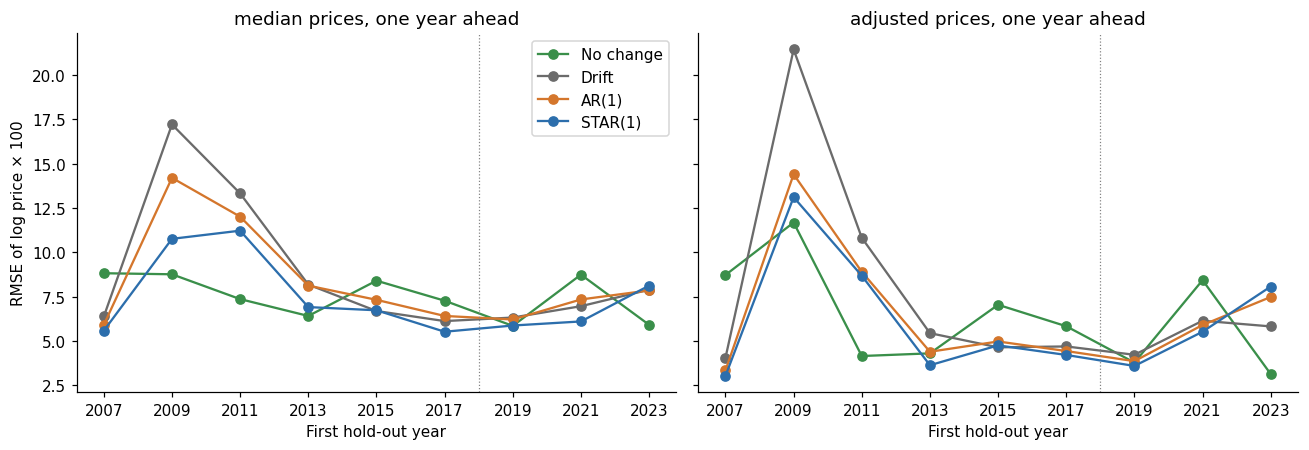

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, measure in zip(axes, MEASURES, strict=True):
    table = first_year.filter(pl.col("measure") == measure).sort("start")
    for name in MAIN:
        ax.plot(table["start"] + 12, table[name], "o-", color=COLORS[name], label=name)
    ax.axvline(2018, color="grey", lw=0.8, ls=":")
    ax.set_xticks((table["start"] + 12).to_list())
    ax.set(xlabel="First hold-out year", title=f"{measure} prices, one year ahead")
axes[0].set(ylabel="RMSE of log price × 100")
axes[0].legend()
fig.tight_layout()
plt.show()

Both measures follow the same rule. When growth in the scored year falls well below the training
average, every growth model over-predicts and no change wins: 2009 and 2011 after the crash, and
2023. When growth holds up near or above that average, no change falls short and the growth models
win: 2007, 2015–2017 and 2021.

The measures differ in how large the swings are, and that explains most of section 4.1.

* **The crash is deeper in adjusted prices.** Growth in 2009 is −10.9% adjusted against −5.9% on
  medians. In a falling market fewer cheap homes sell, which holds the median up. The adjusted
  series removes that, so every forecast misses 2009 by more: STAR(1) by 13.1 against 10.8.
* **Steady years are easier.** In 2007, 2013, 2017, 2019 and 2021 STAR(1)'s one-year error on
  adjusted prices is between 3.0 and 5.5, against 5.5 to 6.9 on medians. Its 2007 error falls from
  5.6 to 3.0.
* **Momentum costs more at a turn.** Training through 2022 ends on two strong years. On adjusted
  prices STAR(1) carries that forward and is 7.3% too high on 2023, against 5.4% on medians, while
  no change, at 3.1, is the most accurate of the four. Three years ahead the 2025 forecast misses by
  18.0 for STAR(1) against 6.3 for no change.

This is why STAR(1) ranks better against the benchmarks on adjusted prices over 2007–2019, where its
gains in 2007 and 2013–2019 outweigh the deeper miss in 2009, and worse over 2019–2025, whose last
origin forecasts the 2023 turn.

In [9]:
lag_rows = []
for measure in MEASURES:
    d = diagnostics.filter(pl.col("measure") == measure)
    for period in PERIODS:
        frame = errors.filter(pl.col("measure") == measure, pl.col("period") == period)
        table = rmse_table(
            frame.filter(
                ((pl.col("protocol") == "one_step") & (pl.col("years_ahead") == 1))
                | ((pl.col("protocol") == "recursive") & (pl.col("years_ahead") == 3))
            ),
            ["protocol"],
            ["STAR(1)", "STAR tuned"],
        )
        chosen = d.filter(pl.col("period") == period)["p_best"]
        lag_rows.append(
            {
                "measure": measure,
                "period": period,
                "windows": chosen.len(),
                "p > 1 chosen": int((chosen > 1).sum()),
                "STAR(1) 1y": table["STAR(1)"][0],
                "tuned 1y": table["STAR tuned"][0],
                "STAR(1) 3y": table["STAR(1)"][1],
                "tuned 3y": table["STAR tuned"][1],
            }
        )
pl.DataFrame(lag_rows)

measure,period,windows,p > 1 chosen,STAR(1) 1y,tuned 1y,STAR(1) 3y,tuned 3y
str,str,i64,i64,f64,f64,f64,f64
"""median""","""2007–2019""",162,67,8.13,8.89,19.35,20.77
"""median""","""2019–2025""",81,45,6.78,6.94,12.16,12.04
"""adjusted""","""2007–2019""",162,54,7.19,9.36,19.76,22.01
"""adjusted""","""2019–2025""",81,62,6.01,6.36,13.74,13.58


### 4.6 Choosing the lag

Cross-validation picks a lag longer than one in 54 to 67 of the 162 earlier windows and in 45 to 62
of the 81 later ones. Over 2007–2019 the tuned model is clearly worse one year ahead under both
measures (8.9 against 8.1 on medians, 9.4 against 7.2 adjusted). Over 2019–2025 it is a little worse
one year ahead and a little better three years ahead. `tune` scores each lag on three one-year errors
of the focal district inside the training window. Errors that size cannot reliably separate lags
whose true accuracy differs by a fraction of a point, so the choice is often decided by noise.
STAR(1) became the headline model after these results were seen, so its lead over the tuned model is
partly a judgement made with hindsight.

In [10]:
STATS = [
    "rho",
    "phi",
    "theta",
    "persistence",
    "ar1_phi_median",
    "corr_own_lag",
    "corr_neighbour_lag",
    "corr_neighbour_same_year",
    "shared_share",
    "corr_shared_lag",
    "corr_own_deviation_lag",
]
(
    diagnostics.group_by("measure", "period")
    .agg(pl.col(*STATS).median())
    .with_columns(setting=pl.col("measure") + ", " + pl.col("period"))
    .drop("measure", "period")
    .unpivot(index="setting")
    .pivot(on="setting", index="variable")
    .select(
        "variable",
        *[f"{m}, {p}" for m in MEASURES for p in PERIODS],
    )
    .with_columns(pl.col(pl.Float64).round(2))
)

variable,"median, 2007–2019","median, 2019–2025","adjusted, 2007–2019","adjusted, 2019–2025"
str,f64,f64,f64,f64
"""rho""",0.72,0.56,0.87,0.8
"""phi""",-0.33,-0.41,-0.24,-0.37
"""theta""",0.44,0.48,0.31,0.47
"""persistence""",0.53,0.49,0.49,0.49
"""ar1_phi_median""",0.29,-0.1,0.45,0.24
"""corr_own_lag""",0.25,-0.2,0.44,0.18
"""corr_neighbour_lag""",0.43,0.22,0.51,0.36
"""corr_neighbour_same_year""",0.76,0.45,0.94,0.83
"""shared_share""",0.66,0.33,0.9,0.74


### 4.7 What the fitted models are doing

The table gives medians across windows of the STAR(1) estimates and of correlations in relative
growth (a node's growth minus its own training average) over the training years.

**Mix noise looks like a district of its own.** On medians over 2007–2019, two thirds of the
variation in relative growth is shared by the whole neighbourhood (`shared_share` 0.66), and a
district's deviation from that shared part reverses the next year (`corr_own_deviation_lag` −0.34).
On adjusted prices the shared part is nine tenths (0.90), the same-year correlation with neighbours
rises from 0.76 to 0.94, and the reversal weakens to −0.20. Much of what looked like district-specific
movement on medians was the mix of homes sold, and it reversed because the mix does. The pattern holds
over 2019–2025, though less strongly (−0.44 to −0.38).

**The fitted coefficients follow.** With less reversal to absorb, the own-lag coefficient $\phi$
moves towards zero (−0.33 to −0.24 over 2007–2019) and the per-district AR(1) coefficient rises (0.29
to 0.45). A node's own growth correlates 0.44 with its previous year on adjusted prices, against 0.25
on medians. $\rho$ rises (0.72 to 0.87) because neighbours move more closely together in the same
year. Persistence, the largest eigenvalue of the fitted dynamics, stays near 0.5 under both measures.

STAR's spatial lag is an average of the neighbourhood, so $\theta$ follows the shared momentum, and a
negative $\phi$ takes out each district's own reversal. On medians the per-district AR(1) has one
coefficient for momentum and reversal together, which is why it falls behind STAR. On adjusted
prices there is less reversal to take out, so the AR(1) comes closer (section 4.4).

## 5. Distance in the weights at district scale

STAR's $W$ uses inverse distance. To test whether distance carries information, the weight is set
proportional to $(d + 10\,\text{m})^{-\alpha}$, with rows scaled to sum to one:

* $\alpha < 0$ gives farther neighbours **more** weight ($\alpha = -1$ weights by distance itself),
* $\alpha = 0$ is equal weights,
* $\alpha = 1$ is the library's inverse distance, which the cell checks reproduces each dataset's $W$
  exactly,
* $\alpha > 1$ concentrates the weight on the nearest neighbours.

If nearer neighbours carry more information, error should fall as $\alpha$ rises through zero, until
the weight sits on too few neighbours. Each entry is STAR(1)'s RMSE minus its RMSE with equal
weights, × 100, pooled over both periods, with intervals that resample the focal districts.

In [11]:
ALPHAS = [-2.0, -1.0, 0.0, 0.5, 1.0, 1.5, 2.0, 3.0]


def alpha_curve(frame, cluster, label):
    """The gap to equal weights at every alpha, one and three years ahead."""
    rows = []
    for horizon in ("1y", "3y"):
        at_horizon = frame.filter(pl.col("horizon") == horizon)
        for alpha in ALPHAS:
            gap, low, high = cluster_gap(at_horizon, f"{alpha:+g}", "+0", cluster)
            rows.append(
                {
                    "setting": label,
                    "horizon": horizon,
                    "alpha": alpha,
                    "vs_equal": gap,
                    "low": low,
                    "high": high,
                }
            )
    return pl.DataFrame(rows)


def show_curve(curve):
    return curve.with_columns(
        cell=pl.format(
            "{} [{}, {}]",
            pl.col("vs_equal").round(3),
            pl.col("low").round(2),
            pl.col("high").round(2),
        )
    ).pivot(on="horizon", index="alpha", values="cell")


frames = []
for (district, _start, measure), ds in datasets.items():
    assert np.allclose(PowerWeightsStar(1.0, p=1).weights(ds), ds.W)
    actual = ds.y_eval()
    for alpha in ALPHAS:
        model = PowerWeightsStar(alpha, p=1)
        for protocol, years in (("one_step", 1), ("recursive", 3)):
            error = holdout_predictions(model, ds, protocol) - actual
            frames.append(
                pl.DataFrame(
                    {
                        "district": district,
                        "measure": measure,
                        "model": f"{alpha:+g}",
                        "horizon": f"{years}y",
                        "err": error[:, years - 1],
                    }
                )
            )
district_alpha = pl.concat(frames)
curves = []
for measure in MEASURES:
    curves.append(
        alpha_curve(
            district_alpha.filter(pl.col("measure") == measure), "district", f"district, {measure}"
        )
    )
    print(
        f"District scale, {measure} prices, STAR(1): RMSE minus equal weights (x100) [95% interval]"
    )
    print(show_curve(curves[-1]))

District scale, median prices, STAR(1): RMSE minus equal weights (x100) [95% interval]
shape: (8, 3)
┌───────┬─────────────────────┬──────────────────────┐
│ alpha ┆ 1y                  ┆ 3y                   │
│ ---   ┆ ---                 ┆ ---                  │
│ f64   ┆ str                 ┆ str                  │
╞═══════╪═════════════════════╪══════════════════════╡
│ -2.0  ┆ 0.075 [-0.03, 0.16] ┆ 0.134 [-0.22, 0.44]  │
│ -1.0  ┆ 0.016 [-0.04, 0.07] ┆ -0.012 [-0.24, 0.18] │
│ 0.0   ┆ 0.0 [0.0, 0.0]      ┆ 0.0 [0.0, 0.0]       │
│ 0.5   ┆ 0.012 [-0.01, 0.04] ┆ 0.072 [-0.04, 0.21]  │
│ 1.0   ┆ 0.039 [-0.01, 0.1]  ┆ 0.184 [-0.02, 0.41]  │
│ 1.5   ┆ 0.078 [0.02, 0.15]  ┆ 0.335 [0.09, 0.6]    │
│ 2.0   ┆ 0.129 [0.05, 0.21]  ┆ 0.517 [0.26, 0.78]   │
│ 3.0   ┆ 0.238 [0.14, 0.33]  ┆ 0.867 [0.59, 1.13]   │
└───────┴─────────────────────┴──────────────────────┘
District scale, adjusted prices, STAR(1): RMSE minus equal weights (x100) [95% interval]
shape: (8, 3)
┌───────┬─────────────────

Between districts the curve is flat around equal weights and rises once the weight concentrates.
Inverse distance is 0.04 above equal weights one year ahead on medians (interval −0.01 to 0.10) and
0.05 above on adjusted prices (−0.10 to 0.20). Weighting by distance itself ($\alpha = -1$) is also
indistinguishable from equal weights. Three years ahead the point estimates rise more steeply with
$\alpha$, and at $\alpha = 3$ both measures are clearly worse than equal weights.

Two readings are possible, and the data support the second as much as the first. Distance may carry
no information between districts. Or the information is too small for this test to see: the
intervals are 0.1 to 0.3 points wide one year ahead, several times the 0.05 gain section 6 finds
between sectors.

## 6. Distance in the weights at sector scale

A postcode sector (`GL5 2`) is a fraction of a district, with tens to a few hundred sales a year.
Neighbouring sectors can differ more than neighbouring districts, and each sector's price is also
noisier.

**Design.**

* **Area.** Every district that appears in any neighbourhood above, with all its cached sales for
  1995–2025, grouped by sector.
* **Prices.** For each origin, the sector median and the adjusted index. The index is computed by
  the library's estimator (`housing_star.data.adjusted.adjusted_levels`) on that window's sales, with
  the hold-out years levelled by training-only effects. This is the same procedure as
  `prices="adjusted"`.
* **Sectors kept.** A sector enters a window if it has at least 20 sales in every year of the window
  under both measures.
* **Model.** About a thousand sectors are too many to fit a STAR per neighbourhood, so the sector
  model is one pooled STAR(1) with $\rho = 0$ (which forecasts as well as full STAR at district
  scale, section 4.1): $z_{i,t+1} = \phi\, z_{i,t} + \theta \sum_j w_{ij} z_{j,t} + \varepsilon$, with
  $z$ a sector's growth minus its training average. $\phi$ and $\theta$ are estimated by least squares
  over every sector and training year.
* **Neighbours.** Every kept sector within 15 km, the district radius, with no cap on the number.
* **Weights tested.** The same exponent grid, plus 20 shufflings of the inverse-distance weights among
  each sector's own neighbours: the same neighbours and weight values, given to the wrong ones.
* **Which noise matters.** The model's inputs come from one measure and the value it is scored
  against from the other, in all four combinations.
* **Intervals.** They resample postcode areas (the letters, such as GL), keeping nearby sectors
  together.

In [12]:
MIN_SALES, SECTOR_RADIUS_KM, SECTOR_SHUFFLES = 20, 15.0, 20
FIRST_YEAR, LAST_YEAR = min(PERIOD_OF), max(PERIOD_OF) + TRAIN_YEARS + HOLDOUT - 1

neighbourhood_districts = sorted(
    {part for ds in datasets.values() for node in ds.postcodes for part in node.split("+")}
)
# One batched download for every district not yet cached, then cache reads.
CACHE.prefetch(neighbourhood_districts, f"{FIRST_YEAR}-01-01", f"{LAST_YEAR + 1}-01-01")
sales = pl.concat(
    [
        CACHE.transactions(d, f"{FIRST_YEAR}-01-01", f"{LAST_YEAR + 1}-01-01")
        for d in neighbourhood_districts
    ]
).select(
    node=node_key_expr("propertyAddress_postcode", "sector"),
    bucket_start=pl.date(pl.col("transactionDate").dt.year(), 1, 1),
    unit=pl.col("propertyAddress_postcode"),
    ptype=pl.col("propertyType"),
    log_price=pl.col("pricePaid").log(),
)
centroids = load_centroids().filter(pl.col("level") == "sector")
sales = sales.filter(pl.col("node").is_in(centroids["key"].implode()))
print(
    f"{len(neighbourhood_districts)} districts, {sales.height:,} sales, "
    f"{sales['node'].n_unique():,} sectors with a centroid"
)

# One panel per origin and measure. The adjusted index is fitted on that window's training years
# only (holdout_from), exactly as `prices="adjusted"` does for a district dataset.
sector_panels = {}
for start in PERIOD_OF:
    window = sales.filter(
        pl.col("bucket_start").dt.year().is_between(start, start + TRAIN_YEARS + HOLDOUT - 1)
    )
    sector_panels[(start, "median")] = window.group_by("node", "bucket_start").agg(
        pl.col("log_price").median().alias("level"), pl.len().alias("n")
    )
    sector_panels[(start, "adjusted")] = adjusted_levels(
        window, holdout_from=date(start + TRAIN_YEARS, 1, 1)
    ).select(
        pl.col("postcode").alias("node"), "bucket_start", pl.col("price").log().alias("level"), "n"
    )
print("sector panels built for", len(PERIOD_OF), "origins")

321 districts, 4,156,573 sales, 1,245 sectors with a centroid


sector panels built for 9 origins


In [13]:
names = sorted(sales["node"].unique().to_list())
where = {s: k for k, s in enumerate(names)}
xy_km = (
    centroids.filter(pl.col("key").is_in(names))
    .sort("key")
    .select("easting", "northing")
    .to_numpy()
    / 1000
)
postcode_area = np.array(["".join(ch for ch in s.split(" ")[0] if ch.isalpha()) for s in names])
pairs = cKDTree(xy_km).query_pairs(SECTOR_RADIUS_KM, output_type="ndarray")
row = np.r_[pairs[:, 0], pairs[:, 1]]
col = np.r_[pairs[:, 1], pairs[:, 0]]
dist_km = np.maximum(np.hypot(*(xy_km[row] - xy_km[col]).T), 0.01)
n_levels = TRAIN_YEARS + HOLDOUT


def sector_weights(keep, values):
    W = sparse.csr_matrix((values[keep], (row[keep], col[keep])), shape=(len(names), len(names)))
    total = np.asarray(W.sum(1)).ravel()
    return sparse.diags(np.where(total > 0, 1 / np.where(total > 0, total, 1), 0.0)) @ W


def growth_matrix(panel, start):
    level = np.full((len(names), n_levels), np.nan)
    kept = panel.filter(pl.col("n") >= MIN_SALES)
    level[
        kept["node"].replace_strict(where).to_numpy(),
        (kept["bucket_start"].dt.year() - start).to_numpy(),
    ] = kept["level"].to_numpy()
    return np.diff(level, axis=1)


rng = np.random.default_rng(0)
frames, sector_stats = [], []
train = np.arange(TRAIN_YEARS - 1)  # growth columns inside the training window
last = train[-1]
for start, period in PERIOD_OF.items():
    growth = {m: growth_matrix(sector_panels[(start, m)], start) for m in MEASURES}
    measured = np.isfinite(growth["median"]).all(1) & np.isfinite(growth["adjusted"]).all(1)
    keep = measured[row] & measured[col]
    use = measured & (np.bincount(row[keep], minlength=len(names)) > 0)
    matrices = {f"{a:+g}": sector_weights(keep, dist_km**-a) for a in ALPHAS}
    for k in range(SECTOR_SHUFFLES):
        order = np.lexsort((rng.random(keep.sum()), row[keep]))  # same row, random neighbour
        shuffled = np.empty(keep.sum())
        shuffled[order] = 1 / dist_km[keep]
        values = np.zeros_like(dist_km)
        values[keep] = shuffled
        matrices[f"shuffled {k}"] = sector_weights(keep, values)
    z = {}
    for m in MEASURES:
        mean = np.zeros(len(names))
        mean[use] = growth[m][use][:, train].mean(1)
        z[m] = np.nan_to_num(growth[m] - mean[:, None]) * use[:, None]
        stats = scale_stats(
            z[m][use][:, train],
            matrices["+1"][use][:, use],
            matrices["+0"][use][:, use],
        )
        sector_stats.append({"start": start, "measure": m, "sectors": int(use.sum()), **stats})
    for source in MEASURES:
        for target in MEASURES:
            mean_out = np.zeros(len(names))
            mean_out[use] = growth[target][use][:, train].mean(1)
            for name, W in matrices.items():
                X = np.vstack(
                    [
                        np.column_stack([z[source][use, t], (W @ z[source][:, t])[use]])
                        for t in train[:-1]
                    ]
                )
                y = np.concatenate([z[target][use, t + 1] for t in train[:-1]])
                phi, theta = np.linalg.lstsq(X, y, rcond=None)[0]

                def step(v, phi=phi, theta=theta, W=W):
                    return phi * v + theta * (W @ v)

                error_1y = mean_out + step(z[source][:, last]) - growth[target][:, last + 1]
                frames.append(
                    pl.DataFrame(
                        {
                            "period": period,
                            "source": source,
                            "target": target,
                            "model": name,
                            "horizon": "1y",
                            "area": postcode_area[use],
                            "err": error_1y[use],
                        }
                    )
                )
                if source == target:
                    v, path = z[source][:, last], []
                    for _ in range(HOLDOUT):
                        v = step(v)
                        path.append(mean_out + v)
                    actual = growth[target][:, last + 1 : last + 1 + HOLDOUT]
                    error_3y = (np.column_stack(path) - actual).sum(1)
                    frames.append(
                        pl.DataFrame(
                            {
                                "period": period,
                                "source": source,
                                "target": target,
                                "model": name,
                                "horizon": "3y",
                                "area": postcode_area[use],
                                "err": error_3y[use],
                            }
                        )
                    )
sector_errors = pl.concat(frames)
sector_stats = pl.DataFrame(sector_stats)
print(
    f"sectors per window: {sector_stats.filter(pl.col('measure') == 'median')['sectors'].to_list()}; "
    f"postcode areas: {len(set(postcode_area))}"
)

sectors per window: [996, 995, 996, 1000, 1004, 1003, 1004, 1013, 1041]; postcode areas: 41


In [14]:
for measure in MEASURES:
    same = sector_errors.filter(pl.col("source") == measure, pl.col("target") == measure)
    curves.append(
        alpha_curve(
            same.filter(~pl.col("model").str.starts_with("shuffled")), "area", f"sector, {measure}"
        )
    )
    print(f"\nSector scale, {measure} prices: RMSE minus equal weights (x100) [95% interval]")
    print(show_curve(curves[-1]))
    for horizon in ("1y", "3y"):
        rmse = (
            same.filter(pl.col("horizon") == horizon)
            .group_by("model")
            .agg((pl.col("err") ** 2).mean().sqrt().mul(100).alias("rmse"))
        )
        equal = rmse.filter(pl.col("model") == "+0")["rmse"].item()
        shuffled = rmse.filter(pl.col("model").str.starts_with("shuffled"))["rmse"] - equal
        print(
            f"  {horizon}: equal weights {equal:.2f}; {len(shuffled)} shuffles of the inverse-distance "
            f"weights {shuffled.min():+.3f} to {shuffled.max():+.3f}"
        )

print("\nSectors, one year ahead: inverse distance minus equal weights, by inputs and target")
for source in MEASURES:
    for target in MEASURES:
        f = sector_errors.filter(
            pl.col("source") == source, pl.col("target") == target, pl.col("horizon") == "1y"
        )
        print(
            f"  inputs {source:>8}, scored on {target:>8}: "
            + show_gap(*cluster_gap(f, "+1", "+0", "area"))
        )
print("\nSectors, adjusted prices, inverse distance minus equal weights, by period")
for period in PERIODS:
    f = sector_errors.filter(
        pl.col("period") == period, pl.col("source") == "adjusted", pl.col("target") == "adjusted"
    )
    for horizon in ("1y", "3y"):
        print(
            f"  {period}, {horizon}: "
            + show_gap(*cluster_gap(f.filter(pl.col("horizon") == horizon), "+1", "+0", "area"))
        )


Sector scale, median prices: RMSE minus equal weights (x100) [95% interval]
shape: (8, 3)
┌───────┬─────────────────────┬───────────────────────┐
│ alpha ┆ 1y                  ┆ 3y                    │
│ ---   ┆ ---                 ┆ ---                   │
│ f64   ┆ str                 ┆ str                   │
╞═══════╪═════════════════════╪═══════════════════════╡
│ -2.0  ┆ 0.153 [0.12, 0.19]  ┆ 0.343 [0.27, 0.41]    │
│ -1.0  ┆ 0.074 [0.05, 0.1]   ┆ 0.161 [0.12, 0.2]     │
│ 0.0   ┆ 0.0 [0.0, 0.0]      ┆ 0.0 [0.0, 0.0]        │
│ 0.5   ┆ -0.015 [-0.03, 0.0] ┆ -0.031 [-0.05, -0.01] │
│ 1.0   ┆ 0.017 [-0.02, 0.05] ┆ 0.057 [0.01, 0.11]    │
│ 1.5   ┆ 0.122 [0.06, 0.18]  ┆ 0.351 [0.27, 0.43]    │
│ 2.0   ┆ 0.283 [0.2, 0.36]   ┆ 0.792 [0.68, 0.9]     │
│ 3.0   ┆ 0.579 [0.48, 0.67]  ┆ 1.553 [1.41, 1.7]     │
└───────┴─────────────────────┴───────────────────────┘
  1y: equal weights 9.47; 20 shuffles of the inverse-distance weights +0.026 to +0.056
  3y: equal weights 18.27; 20 shuffles

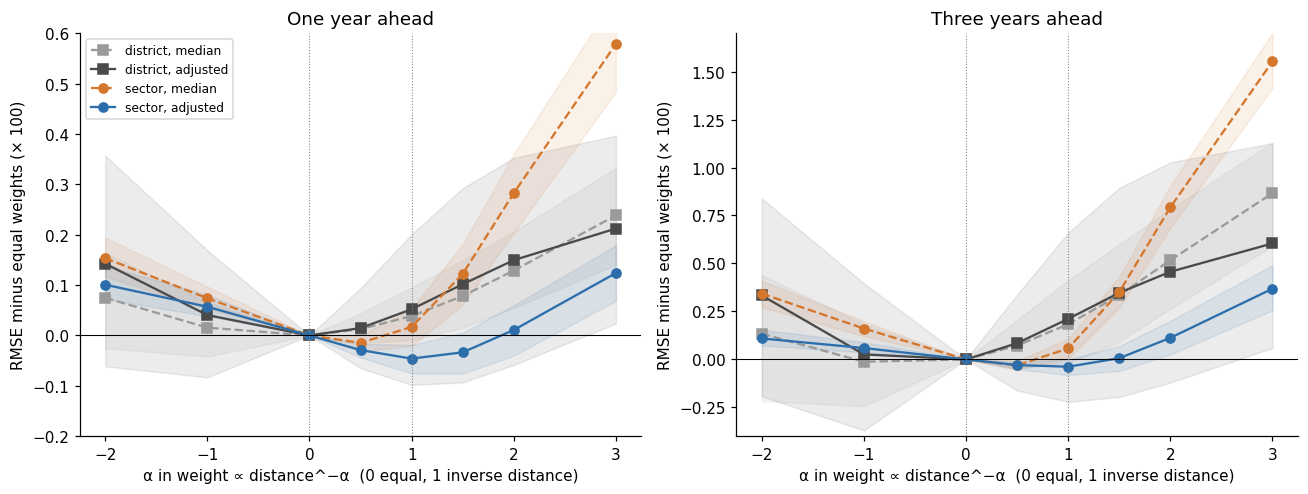

In [15]:
curve = pl.concat(curves)
styles = {
    "district, median": ("#9a9a9a", "s", "--"),
    "district, adjusted": ("#4a4a4a", "s", "-"),
    "sector, median": ("#d4762c", "o", "--"),
    "sector, adjusted": ("#2c6eac", "o", "-"),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, horizon, title in zip(
    axes, ("1y", "3y"), ("One year ahead", "Three years ahead"), strict=True
):
    for setting, (color, marker, ls) in styles.items():
        c = curve.filter(pl.col("setting") == setting, pl.col("horizon") == horizon).sort("alpha")
        ax.plot(c["alpha"], c["vs_equal"], marker=marker, ls=ls, color=color, label=setting)
        ax.fill_between(c["alpha"], c["low"], c["high"], color=color, alpha=0.10)
    ax.axhline(0, color="black", lw=0.7)
    for x in (0, 1):
        ax.axvline(x, color="grey", lw=0.7, ls=":")
    ax.set(
        title=title,
        xlabel="α in weight ∝ distance^−α  (0 equal, 1 inverse distance)",
        ylabel="RMSE minus equal weights (× 100)",
        ylim=(-0.2, 0.6) if horizon == "1y" else (-0.4, 1.7),
    )
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

**Sectors with adjusted prices.** Error falls from far-weighting to equal weights to inverse
distance, and rises again once the weight concentrates. Inverse distance is 0.046 below equal weights
one year ahead (interval −0.08 to −0.02) and 0.038 below three years ahead (−0.08 to −0.00).
Weighting by distance itself is 0.06 worse than equal weights. The 20 shufflings are all at or above
equal weights (+0.002 to +0.020 one year ahead), so the gain comes from giving the larger weights to
the nearer sectors. One year ahead it holds in both periods (−0.05 each). Three years ahead it is
clear over 2019–2025 (−0.11) and not separable from zero over 2007–2019 (−0.01).

**Sectors with medians.** Farther-weighting is again clearly worse (+0.074 one year ahead), and a
mild decay ($\alpha = 0.5$) is slightly better than equal weights (−0.015, interval −0.03 to 0.00).
Inverse distance ties one year ahead (+0.017, −0.02 to 0.05) and is slightly worse three years
ahead (+0.057, 0.01 to 0.11), and steeper decay is much worse.

**Which noise hides it.** With adjusted inputs, inverse distance beats equal weights whether it is
scored on adjusted prices (−0.05) or on medians (−0.03). With median inputs it does not, against
either target (+0.02 and +0.03). Noise in the value forecast adds roughly the same error to every
weighting, so it cannot change which wins. Noise in the inputs can. Inverse distance takes much of a
sector's spatial term from its nearest few neighbours, so their mix noise passes into the forecast,
while equal weights average it away over about forty sectors.

The chart puts the four curves side by side. Only the adjusted sector curve falls below zero.

## 7. Why districts and sectors differ

The table measures the spatial structure of relative growth over the training years at each scale
and under each measure, as medians across windows:

* `neighbours`: neighbours per node;
* `same_year`: the correlation of a node's growth with its inverse-distance neighbour average in the
  same year;
* `avg_vs_equal`: the correlation between the inverse-distance and the equal-weight neighbour
  averages, that is, how different the two weightings' inputs are;
* `own_reversal`: the lag-one correlation of a node's growth minus its neighbours' average. A
  negative value means a high year tends to be followed by a low one, the mark of measurement noise.

In [16]:
district_scale = (
    diagnostics.group_by("measure")
    .agg(pl.col("neighbours", "same_year", "avg_vs_equal", "own_reversal").median())
    .with_columns(scale=pl.lit("district"))
)
sector_scale = (
    sector_stats.group_by("measure")
    .agg(pl.col("neighbours", "same_year", "avg_vs_equal", "own_reversal").median())
    .with_columns(scale=pl.lit("sector"))
)
(
    pl.concat([district_scale, sector_scale])
    .with_columns(setting=pl.col("scale") + ", " + pl.col("measure"))
    .drop("scale", "measure")
    .unpivot(index="setting")
    .pivot(on="setting", index="variable")
    .select("variable", *[f"{s}, {m}" for s in ("district", "sector") for m in MEASURES])
    .with_columns(pl.col(pl.Float64).round(2))
)

variable,"district, median","district, adjusted","sector, median","sector, adjusted"
str,f64,f64,f64,f64
"""neighbours""",12.0,12.0,41.0,41.0
"""same_year""",0.7,0.92,0.61,0.86
"""avg_vs_equal""",0.99,1.0,0.98,0.99
"""own_reversal""",-0.38,-0.28,-0.44,-0.33


Three things separate the scales.

1. **How different the weightings' inputs are.** Between districts the inverse-distance and
   equal-weight averages correlate 0.99 on medians and 1.00 on adjusted prices. A neighbourhood is
   about twelve districts that move almost together, so any sensible average of them is nearly the
   same series, and the weighting has almost nothing to work on. Between sectors the two averages
   still correlate 0.98–0.99, but each sector has about 41 neighbours across 15 km. The nearest few,
   within a kilometre or two, are a distinct part of that average, and section 6 shows that they
   carry a little more information about the sector.
2. **How noisy each node is.** Sectors reverse more than districts (`own_reversal` −0.44 against
   −0.38 on medians), because each sector's price rests on fewer sales. That noise is what leaning on
   the nearest neighbours amplifies. Adjusting for the mix reduces it at both scales (−0.33 for sectors,
   −0.28 for districts). That is enough to let the sectors' distance signal through.
3. **How much data each test has.** The sector test pools about a thousand sectors per window across
   41 postcode areas. The district test has 27 focal neighbourhoods of about thirteen nodes. Its
   intervals are wider than the whole effect the sector test finds, so a gain of that size between
   districts would go undetected.

The district result does not show that distance is irrelevant between districts. It shows that, at
that scale, it cannot be told apart from equal weights, and that concentrating the weight is
harmful.

## 8. Discussion

**On the benchmarks.** No growth model here anticipates a change in the growth rate. Each wins the
years in which its assumption about growth holds. The drift and STAR forecasts carry the training
average forward, and no change assumes none. That is why the ranking turns on the period, and why
no change is so hard to beat three years ahead across a crash. Adjusted prices sharpen both sides of
this. They show the real momentum in prices, which pays while it lasts, and the real depth of a fall,
which no model foresaw.

**On the price measure.** Medians mix two signals, the price of a given home and which homes sold.
The second looks like district-specific growth that reverses, and the models spend coefficients on
it: a negative own lag, a weaker AR(1). On adjusted prices that structure largely disappears.
Neighbouring districts move together more, growth is more persistent, and on a common target the
models forecast price change better. For a question about what a given home is worth, adjusted
prices are the better input.

**On distance.** Nearer neighbours carry more information than farther ones, and the shuffled
weights show it is distance, not the set of neighbours, that matters. The effect is small and appears
only where neighbours differ, at sector scale, and where their prices are measured cleanly. Inverse
distance is a reasonable default: it is never meaningfully worse than equal weights at either scale,
and at sector scale with adjusted prices it is the best of the weightings tested. A steep decay
($\alpha \ge 2$) is not a reasonable default; it is clearly worse at both scales on medians.

**For scenarios.** In [notebook 02](02_scenarios.ipynb) a shock spreads to neighbours through $W$.
Between districts, how that effect is shared by distance is an assumption the data cannot check.
Between sectors with adjusted prices, it has support.

## 9. Limitations

* **One sample.** The sample is 27 districts and nine overlapping origins, scored in two periods, the
  second added after the first was seen. The intervals treat districts as independent, but
  neighbourhoods overlap (NR5 and NR8, WN1 and WN5 share neighbours), so they are too narrow if
  anything.
* **What the adjustment covers.** The adjusted index holds location (unit postcode) and property type
  fixed. It cannot see floor area, condition or improvements, which Land Registry does not record, or
  tenure, which is not cached. Sales more than about a factor of two from their fitted value are
  trimmed.
* **Errors on different series.** Errors on each measure are against that measure's own series.
  Only section 4.4 compares the measures on a common target, and it pools both periods.
* **The sector model.** At sector scale the model is a pooled STAR with $\rho = 0$, not the library's
  per-neighbourhood STAR. Sectors need 20 sales in every year of a window, which favours urban areas.
  Sector intervals cluster by postcode area, which is coarser than the spatial correlation itself.
* **What the evaluation leaves out.** No model uses interest rates, incomes, credit or supply. The
  turning points that decide the rankings are, by construction, outside what these models can
  forecast.
* **Choices made after seeing results.** STAR(1) became the headline specification after the
  lag-tuning results were seen.

## 10. Conclusions

* **Q1.** STAR(1) beats the AR(1) and drift benchmarks on medians in both periods. Whether it beats
  the no-change forecast depends on whether growth holds up after the forecast origin. Three years
  ahead across the 2008 crash, no change is best.
* **Q2.** Adjusted prices change the ranking by period: STAR(1) ranks better against the benchmarks
  over 2007–2019 and worse over 2019–2025, because adjusted series carry more momentum into a turn. Scored on a common
  target, models built on adjusted prices forecast price change better one year ahead.
* **Q3.** Distance carries information between sectors with adjusted prices. Inverse distance beats
  equal weights there, and shuffling the weights loses the gain. Between districts it cannot be told
  apart from equal weights under either measure, and steep decay is harmful at both scales on
  medians.
* **Q4.** The scales differ because neighbouring districts move almost together, because sector
  medians are noisy, and because the district test has less power than the effect requires.

**For the library.** Inverse-distance weights are a sound default. Adjusted prices are the better
input when the question is what prices of a given kind of home will do, and the necessary input if
distance in $W$ is to matter at sector scale. Neither choice turns these models into forecasters of
turning points.

## 11. Choosing a configuration: practical guidance

This section turns the results into advice for someone using the models. No configuration wins
everywhere. **The period decides more than any setting**: every growth model carries the recent
trend forward, so it does well while the trend lasts and badly when it turns, and nothing here
anticipates a turn. Each point below is marked as **evidence** (a result in this notebook, with its
section) or **reasoning** (what follows from how the models work, not tested directly).

### Adjusted prices or medians

**Use adjusted prices when**

* **the question is what a given kind of home will be worth.** That covers revaluing a property,
  tracking price change, or anything close to a house price index. Scored against that target,
  models built on adjusted prices forecast better one year ahead (evidence, section 4.4).
* **you model small areas (sectors).** A sector median rests on a few dozen sales, so which homes
  happened to sell swamps the price signal. Adjusted prices remove much of that (evidence, sections
  6 and 7).
* **the model leans on a single series**, such as the AR(1) or STAR with a steep distance decay. On
  medians these models are fed mix noise that looks like growth and then reverses. The AR(1) gains
  most of all from adjusted prices (evidence, sections 4.4 and 4.7).

**Use medians when**

* **the quantity of interest is the median sale price itself**, such as the typical price paid in an
  area or a figure to match published median statistics. The median includes the mix of homes sold
  by definition, and that is part of what is being forecast (reasoning).
* **you work at district scale and want the simplest series.** With hundreds of sales a period, mix
  noise largely averages out, and STAR's neighbourhood average absorbs much of what is left
  (evidence, sections 4.1 and 4.7).

**Caveats for adjusted prices.** They cannot see floor area, condition or improvements, which Land
Registry does not record. They show the real swings, including deeper falls, so models built on them
carry more momentum into a turn. In 2023, STAR(1) on adjusted prices over-predicted by 7.3%,
against 5.4% on medians (evidence, section 4.5).

### Which model, for structural reasons

| Model | Use it when | Why |
|---|---|---|
| **No change** | the horizon is long (three years or more), or there is no good reason to expect the recent trend to last | The training-window average growth is the largest source of error when the market turns, and no change has no trend to get wrong. Across the 2008 crash it was best three years ahead under both measures (evidence, sections 4.1–4.2). It is systematically too low whenever prices keep rising. |
| **Drift** | growth is steady, recent deviations from trend are expected to fade, or neighbours carry little information | It ignores short-run momentum. That is a strength after a surge that does not last, which is why it beat STAR(1) on adjusted prices over 2019–2025, when the 2021–22 boom stopped in 2023 (evidence, sections 4.1 and 4.5). |
| **AR(1)** | the area is isolated, with few neighbours that have data, and has a long, clean history of its own, ideally on adjusted prices | It uses only the area's own momentum. On medians that momentum is mostly mix noise and it does poorly; on adjusted prices it comes close to STAR (evidence, sections 4.1, 4.4 and 4.7). |
| **STAR(1)** | areas share a market (towns, suburbs, clusters of districts) and the horizon is about a year | Neighbours' recent growth is a cleaner signal of shared momentum than any one area's own history, because averaging cancels noise. That is its structural advantage, clearest on medians, where single-area noise is worst (evidence, sections 4.2 and 4.7). |

**STAR settings.** Keep the lag at one: choosing it by cross-validation picks noise and forecasts
worse (evidence, section 4.6). The same-year coefficient $\rho$ makes little difference to forecasts
(evidence, section 4.1). Avoid a steep distance decay ($\alpha \ge 2$) (evidence, sections 5–6).

**Luck and structure.** Which model wins in a given window depends mostly on whether growth held up
after the forecast origin, and that is luck of the period. The structural parts are these:

* no change tends to win at long horizons across uncertain periods;
* STAR beats the AR(1) and drift where neighbours move together and prices are noisy;
* adjusted prices make the dynamic models sharper in steady markets and riskier at a turn.

### District or sector

**Model districts when**

* a robust forecast for a broad area is enough;
* the area is rural or thinly traded, where sectors often fall short of 20 sales a year;
* you use medians;
* you want the default. Between districts the choice of distance weights cannot be shown to matter,
  so $W$ is not a decision to worry about (evidence, section 5).

**Model sectors when**

* local detail matters, such as one part of a town against another;
* you have adjusted prices and enough sales per sector, which in practice means towns and suburbs;
* a scenario's effect should fall off with distance. Only at sector scale with adjusted prices do the
  data support that (evidence, section 6).

**What has not been tested at sector scale.** Section 6 uses a pooled model with $\rho = 0$, not the
library's per-neighbourhood STAR. The library's default of 15 nodes would cover only a few kilometres
of sectors in a town, so the best radius and number of nodes at that scale is still an open question.

### Starting points

| Task | Configuration |
|---|---|
| Next year's typical price in a district | district scale, medians or adjusted prices, STAR(1), checked against no change |
| Price change for a given kind of home | adjusted prices, STAR(1) or AR(1) |
| Local detail within a town | sectors, adjusted prices, STAR(1) with inverse-distance weights |
| Three or more years ahead, or an uncertain market | treat no change as the benchmark to beat; do not trust a trend-following model at a turn |
| Scenarios about a specific neighbour | sectors with adjusted prices; at district scale, report the equal-weights result alongside ([notebook 02](02_scenarios.ipynb)) |

All of this rests on 27 districts and two periods. Treat it as well-founded guidance, not settled
law. The tested results, the same-target comparison and the sector distance result, are the
strongest parts; the explanations of why each model has its strengths fit the results but are not
tested directly.